# Actividad · Clustering de clientes con restricciones

Una empresa desea agrupar 12 clientes ficticios usando su frecuencia mensual de compra y ticket promedio. Debe construir exactamente tres grupos de 3 a 5 clientes.

1. **Exploración y escalado.** Visualizar los datos y explicar por qué no conviene sumar directamente distancias entre variables con unidades diferentes.
2. **Modelo base.** Asignar cada cliente a un grupo y minimizar la suma de distancias cuadráticas entre pares del mismo grupo. Incluir los límites de tamaño.
3. **Conocimiento adicional.** Resolver incorporando `must-link`: C01–C02 y C05–C06; `cannot-link`: C01–C03 y C09–C10. Las restricciones son condiciones hipotéticas de negocio.
4. **Comparación.** Comparar asignaciones, tamaños, costo y gráficos con y sin restricciones por pares. Comprobar que se satisfacen todas las condiciones.
5. **Inviabilidad.** Analizar el caso `must-link`: C01–C02 y C02–C03; `cannot-link`: C01–C03. Explicar el resultado del solver y proponer una modificación coherente.


In [ ]:
import importlib.util, subprocess, sys
faltantes = [p for p in ["pandas", "ortools", "matplotlib"] if importlib.util.find_spec(p) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from ortools.sat.python import cp_model
from itertools import combinations, product
from importlib.metadata import version
print({p: version(p) for p in ["pandas", "ortools", "matplotlib"]})

{'pandas': '2.2.3', 'ortools': '9.15.6755', 'matplotlib': '3.10.8'}


## 1. Datos y escalado
Se usa estandarización con desviación poblacional (`ddof=0`) en ambas variables. Así, una diferencia de una desviación estándar tiene el mismo peso en cada dimensión.

,cliente,compras_mes,ticket_soles
0,C01,1,20
1,C02,2,22
2,C03,2,27
3,C04,3,24
4,C05,7,65
5,C06,8,68
6,C07,8,74
7,C08,9,70
8,C09,14,120
9,C10,15,126


,compras_z,ticket_z
0,-1.368335,-1.275168
1,-1.181744,-1.225486
2,-1.181744,-1.101282
3,-0.995153,-1.175805
4,-0.248788,-0.157326
5,-0.062197,-0.082803
6,-0.062197,0.066243
7,0.124394,-0.033121
8,1.057350,1.208926
9,1.243941,1.357971


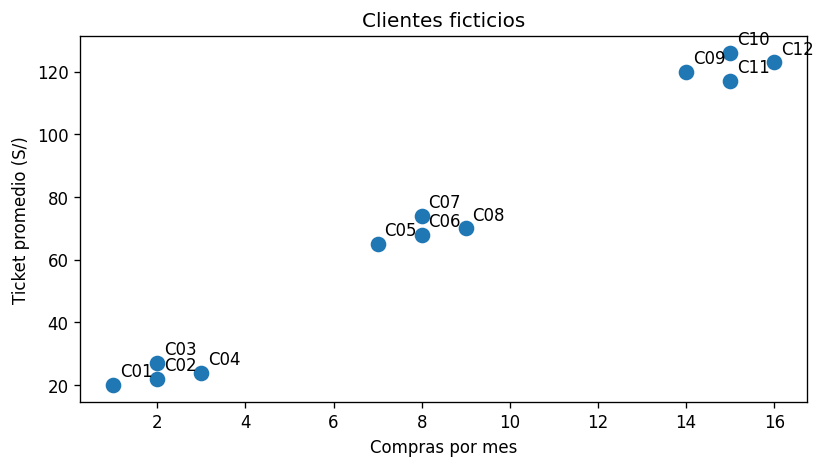

In [ ]:
clientes = pd.DataFrame({
 "cliente":[f"C{i:02}" for i in range(1,13)],
 "compras_mes":[1,2,2,3,7,8,8,9,14,15,15,16],
 "ticket_soles":[20,22,27,24,65,68,74,70,120,126,117,123]
})
X = clientes[["compras_mes","ticket_soles"]].to_numpy(dtype=float)
Z = (X-X.mean(axis=0))/X.std(axis=0, ddof=0)
n = len(clientes)
K = 3
pares = list(combinations(range(n),2))
# CP-SAT opera con enteros: escalamos y redondeamos los costos.
ESCALA = 1000
costos = {(i,j): int(round(ESCALA*np.sum((Z[i]-Z[j])**2))) for i,j in pares}
display(clientes)
display(pd.DataFrame(Z, columns=["compras_z","ticket_z"]))
plt.figure(figsize=(7,4))
plt.scatter(X[:,0],X[:,1],s=70)
for i, nombre in enumerate(clientes.cliente):
    plt.annotate(nombre, X[i], xytext=(4,5), textcoords="offset points")
plt.xlabel("Compras por mes"); plt.ylabel("Ticket promedio (S/)")
plt.title("Clientes ficticios"); plt.tight_layout(); plt.show(); plt.close()

## 2. Formulación
Sea $c_i\in\{0,1,2\}$ el grupo del cliente $i$. Se define $x_{ig}=1\iff c_i=g$ y $y_{ij}=1\iff c_i=c_j$.

**Tamaño:** $3\leq\sum_i x_{ig}\leq5$ para cada grupo $g$. Todos los grupos deben estar ocupados.

**Pares:** `must-link` impone $c_i=c_j$; `cannot-link` impone $c_i\neq c_j$.

**Objetivo:** minimizar $\sum_{i<j}w_{ij}y_{ij}$, con $w_{ij}=\operatorname{round}(1000\lVert z_i-z_j\rVert^2)$.

Fijamos $c_0=0$ para eliminar parte de la simetría de etiquetas. No elimina particiones posibles porque los nombres de los grupos son intercambiables.

Se reporta el óptimo del **costo entero redondeado**. La suma sin redondear se calcula aparte. La suma de distancias por pares favorece grupos compactos, pero depende también del tamaño; aquí se controla con límites explícitos.

In [ ]:
def resolver(must_link=(), cannot_link=()):
    modelo = cp_model.CpModel()
    grupo = [modelo.new_int_var(0,K-1,f"c_{i}") for i in range(n)]
    pertenece = [[modelo.new_bool_var(f"x_{i}_{g}") for g in range(K)] for i in range(n)]
    for i in range(n):
        for g in range(K):
            modelo.add(grupo[i] == g).only_enforce_if(pertenece[i][g])
            modelo.add(grupo[i] != g).only_enforce_if(pertenece[i][g].Not())
        modelo.add(sum(pertenece[i]) == 1)
    for g in range(K):
        modelo.add(sum(pertenece[i][g] for i in range(n)) >= 3)
        modelo.add(sum(pertenece[i][g] for i in range(n)) <= 5)
    mismo = {}
    for i,j in pares:
        mismo[i,j] = modelo.new_bool_var(f"y_{i}_{j}")
        modelo.add(grupo[i] == grupo[j]).only_enforce_if(mismo[i,j])
        modelo.add(grupo[i] != grupo[j]).only_enforce_if(mismo[i,j].Not())
    for i,j in must_link:
        modelo.add(grupo[i] == grupo[j])
    for i,j in cannot_link:
        modelo.add(grupo[i] != grupo[j])
    modelo.add(grupo[0] == 0)
    modelo.minimize(sum(costos[p]*mismo[p] for p in pares))
    solver = cp_model.CpSolver()
    solver.parameters.num_search_workers = 1
    solver.parameters.random_seed = 42
    solver.parameters.max_time_in_seconds = 60
    estado = solver.solve(modelo)
    salida = {"estado":solver.status_name(estado), "grupos":None}
    if estado in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        salida.update(grupos=[solver.value(v) for v in grupo],
                      costo=int(round(solver.objective_value)),
                      cota=solver.best_objective_bound)
    return salida

base = resolver()
print(base)
assert base["estado"] == "OPTIMAL", "Se requiere demostrar optimalidad para esta comparación"


{'estado': 'OPTIMAL', 'grupos': [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2], 'costo': 1116, 'cota': 1116.0}


## 3. Restricciones de negocio
Los identificadores se convierten a índices. Algunas restricciones `cannot-link` separan clientes cercanos para hacer visible el conflicto entre proximidad y condiciones obligatorias. No se derivan automáticamente de la distancia.

In [ ]:
indice = {nombre:i for i,nombre in enumerate(clientes.cliente)}
def pares_indices(pares_nombres):
    return [(indice[a],indice[b]) for a,b in pares_nombres]
ML = pares_indices([("C01","C02"),("C05","C06")])
CL = pares_indices([("C01","C03"),("C09","C10")])
restringido = resolver(ML, CL)
print(restringido)
assert restringido["estado"] == "OPTIMAL", "No se ha demostrado optimalidad"
comparacion = clientes.copy()
comparacion["grupo_base"] = np.array(base["grupos"])+1
comparacion["grupo_restringido"] = np.array(restringido["grupos"])+1
display(comparacion)
# Las etiquetas son arbitrarias: comparar pertenencia conjunta, no solo números.


{'estado': 'OPTIMAL', 'grupos': [0, 0, 2, 0, 0, 0, 2, 2, 2, 1, 1, 1], 'costo': 35101, 'cota': 35101.0}


,cliente,compras_mes,ticket_soles,grupo_base,grupo_restringido
0,C01,1,20,1,1
1,C02,2,22,1,1
2,C03,2,27,1,3
3,C04,3,24,1,1
4,C05,7,65,2,1
5,C06,8,68,2,1
6,C07,8,74,2,3
7,C08,9,70,2,3
8,C09,14,120,3,3
9,C10,15,126,3,2


## 4. Validaciones independientes y costo
Verificamos las asignaciones recuperadas, los tamaños y el costo recalculado desde los datos. Las restricciones adicionales no pueden mejorar el valor óptimo del mismo problema de minimización.

Pares cuya pertenencia conjunta cambia: 21


,tamanos,costo_entero,costo_entero_div_1000,costo_sin_redondear
Base,"[4, 4, 4]",1116,1.116,1.118209
Con restricciones,"[5, 3, 4]",35101,35.101,35.102993


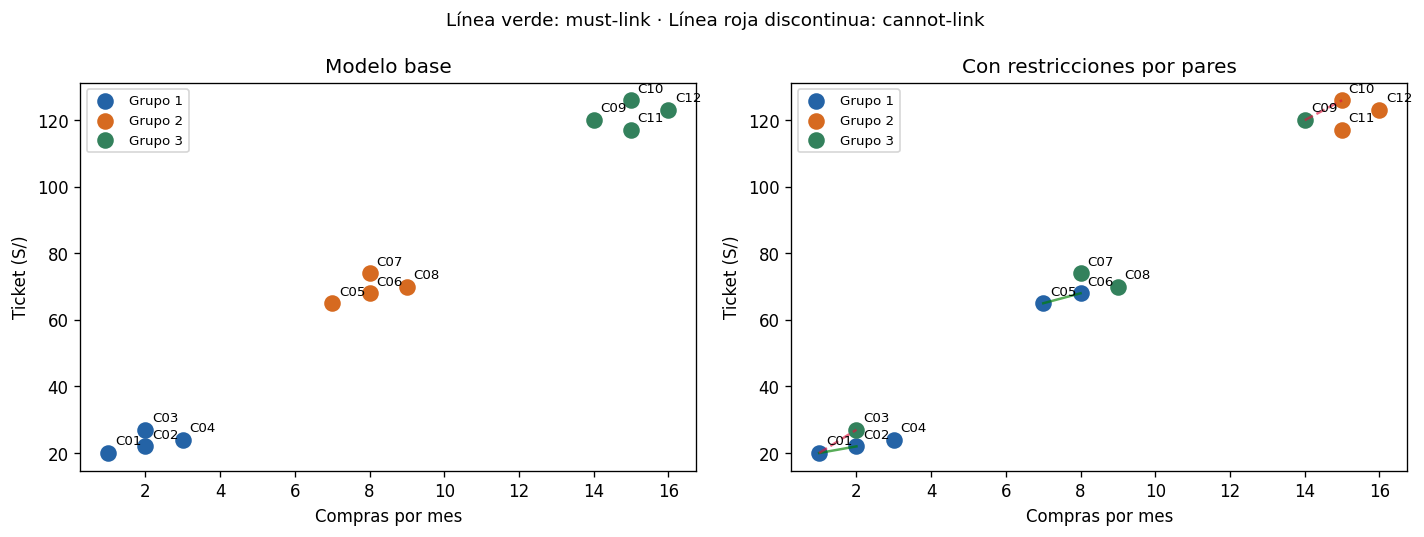

In [ ]:
def verificar(resultado, ml=(), cl=()):
    g = resultado["grupos"]
    assert g is not None and len(g) == n
    assert all(0 <= v < K for v in g)
    tamanos = [g.count(k) for k in range(K)]
    assert all(3 <= t <= 5 for t in tamanos)
    assert all(g[i] == g[j] for i,j in ml)
    assert all(g[i] != g[j] for i,j in cl)
    costo = sum(costos[i,j] for i,j in pares if g[i] == g[j])
    assert costo == resultado["costo"]
    assert abs(resultado["cota"]-costo) < 1e-6
    exacto = sum(float(np.sum((Z[i]-Z[j])**2)) for i,j in pares if g[i] == g[j])
    return {"tamanos":str(tamanos), "costo_entero":costo,
            "costo_entero_div_1000":costo/ESCALA, "costo_sin_redondear":exacto}

resumen = pd.DataFrame([verificar(base),verificar(restringido,ML,CL)],
                       index=["Base","Con restricciones"])
assert restringido["costo"] >= base["costo"]
display(resumen)
print("Pares cuya pertenencia conjunta cambia:", sum(
    (base["grupos"][i] == base["grupos"][j]) !=
    (restringido["grupos"][i] == restringido["grupos"][j]) for i,j in pares))

fig, axes = plt.subplots(1,2,figsize=(12,4.5))
colores = ["#2463a6", "#d66a20", "#33815c"]
for ax, resultado, titulo in zip(axes,[base,restringido],["Modelo base","Con restricciones por pares"]):
    g = np.array(resultado["grupos"])
    for k in range(K):
        puntos = X[g == k]
        ax.scatter(puntos[:,0],puntos[:,1],s=80,color=colores[k],label=f"Grupo {k+1}")
    for i,nombre in enumerate(clientes.cliente):
        ax.annotate(nombre,X[i],xytext=(4,5),textcoords="offset points",fontsize=8)
    if titulo.startswith("Con"):
        for lista, color, estilo in [(ML,"green","-"),(CL,"crimson","--")]:
            for i,j in lista:
                ax.plot(X[[i,j],0],X[[i,j],1],color=color,linestyle=estilo,alpha=.65)
    ax.set_title(titulo); ax.set_xlabel("Compras por mes"); ax.set_ylabel("Ticket (S/)")
    ax.legend(fontsize=8)
fig.suptitle("Línea verde: must-link · Línea roja discontinua: cannot-link",fontsize=11)
plt.tight_layout(); plt.show(); plt.close()


## 5. Caso inviable
Si C01 comparte grupo con C02 y C02 con C03, la transitividad exige que C01 comparta grupo con C03. Prohibir simultáneamente esa última relación hace imposible cualquier asignación, sin importar las distancias.

In [ ]:
ml_conflicto = pares_indices([("C01","C02"),("C02","C03")])
cl_conflicto = pares_indices([("C01","C03")])
conflicto = resolver(ml_conflicto, cl_conflicto)
print("Caso contradictorio:", conflicto["estado"])
assert conflicto["estado"] == "INFEASIBLE"
assert conflicto["grupos"] is None
# Modificación explícita del escenario didáctico: retirar la incompatibilidad contradictoria.
corregido = resolver(ml_conflicto, [])
assert corregido["estado"] == "OPTIMAL"
verificar(corregido, ml_conflicto, [])
print("Caso sin la incompatibilidad contradictoria:", corregido["estado"])
print("Todas las verificaciones de clustering pasaron.")

Caso contradictorio: INFEASIBLE
Caso sin la incompatibilidad contradictoria: OPTIMAL
Todas las verificaciones de clustering pasaron.


## 6. Conclusiones
- La solución base prioriza cercanía con tamaños válidos. Las restricciones por pares pueden obligar a separar clientes cercanos y unir otros más lejanos; el costo óptimo no puede disminuir al añadir condiciones.
- Las etiquetas de los grupos son arbitrarias. Para comparar particiones, importa si dos clientes comparten grupo, no si su número de grupo cambió.
- `must-link` es transitiva por la igualdad de etiquetas. `cannot-link` no lo es: que A esté separado de B y B de C no exige separar A de C.
- Los indicadores de igualdad se modelan en ambas direcciones; de otro modo, el objetivo podría ignorar distancias de pares realmente unidos.
- El objetivo utilizado es de distancias por pares. Para un grupo de tamaño $m$, su suma de distancias cuadráticas por pares equivale a $m$ veces la suma de distancias cuadráticas a su centroide. Con tamaños variables, no es equivalente al objetivo de K-means.
- `INFEASIBLE` significa que el solver demostró que no existe una solución. Un estado `UNKNOWN` por límite de tiempo no significa lo mismo. El notebook exige optimalidad para sus comparaciones y nunca consulta asignaciones de un caso inviable.
- Retirar una condición solo es apropiado si el responsable del problema acepta modificarla; en el ejemplo se hace como escenario didáctico explícito.

**Extensión opcional:** comparar tamaños exactos de 4 clientes por grupo frente al rango de 3 a 5, manteniendo los mismos costos y restricciones por pares.

**Referencia técnica:** [OR-Tools CP-SAT](https://developers.google.com/optimization/cp/cp_solver).